# Epilogue · Inference from scratch

<a href="https://colab.research.google.com/github/umanets/pixelsprite/blob/main/learn/09_inference_from_scratch.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

The last case file: write your own drawing loop for the real model, check that it produces **exactly** the same
sprites as the library, and then find out why the library is many times faster (the key/value cache).

**Time:** about 4 minutes on a laptop CPU. **You will learn:** what "inference" really is, the prefix, the
autoregressive loop, guidance written by hand, reproducibility with seeds, and the KV cache.

In [1]:
try:
    import pixelsprite
except ImportError:
    %pip -q install "pixelsprite[learn] @ git+https://github.com/umanets/pixelsprite"
import os, warnings
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")
warnings.filterwarnings("ignore")
from huggingface_hub.utils import logging as hf_logging
hf_logging.set_verbosity_error()

In [2]:
import time
import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import display
from pixelsprite import SpritePipeline, sample, sheet, rgba_from_index
from pixelsprite.model import edge_flags
from pixelsprite.sampling import split_pick

pipe = SpritePipeline.from_pretrained(device="cpu")      # CPU keeps the numbers exactly comparable
model, palette = pipe.model, pipe.palette
text = pipe.embed(["frost sword"])

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 3777.49it/s]

## 1. The naive loop
Inference is just this: start with the prefix (caption, size, "no silhouette given"), then repeat 256 times:
run the **whole** sequence so far through the network, take the scores for the next pixel, pick a token, append it.
With guidance we run it twice per step: with the caption and with the "null" caption.

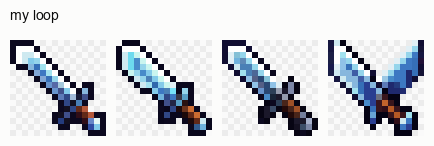

naive loop: 82.7s for 4 sprites


In [3]:
@torch.no_grad()
def draw_naive(text, n=4, g_shape=1.0, g_colour=2.0, seed=0):
    gen = torch.Generator().manual_seed(seed)
    S, N = 16, 256
    ar = torch.arange(N)
    rows, cols = (ar // S).expand(n, -1), (ar % S).expand(n, -1)
    mask = torch.zeros(n, S, S, dtype=torch.bool); known = torch.zeros(n, dtype=torch.bool)
    edge = edge_flags(mask, known)
    cond_c = model.cond(text.expand(n, -1))                 # "with the caption"
    cond_u = model.cond(None, batch=n)                      # "without": the learned null caption
    prev = torch.full((n, 1), model.BOS)                    # the first input token is BOS ("begin")
    out = []
    for t in range(N):
        T = prev.shape[1]
        lc = model(cond_c, S, mask, known, prev, rows[:, :T], cols[:, :T], edge[:, :T])[:, -1]   # whole sequence!
        lu = model(cond_u, S, mask, known, prev, rows[:, :T], cols[:, :T], edge[:, :T])[:, -1]
        tok = split_pick(lc, lu, g_shape, g_colour, 1.0, 1.0, gen, empty_id=model.EMPTY)
        out.append(tok)
        prev = torch.cat([prev, tok[:, None]], 1)
    idx = torch.stack(out, 1)
    return torch.where(idx == model.EMPTY, -1, idx).view(n, S, S).numpy()

t = time.time(); mine = draw_naive(text, n=4, seed=7); t_naive = time.time() - t
display(sheet([rgba_from_index(x, palette) for x in mine], "my loop", scale=6, cols=4))
print(f"naive loop: {t_naive:.1f}s for 4 sprites")

## 2. The library, same seed

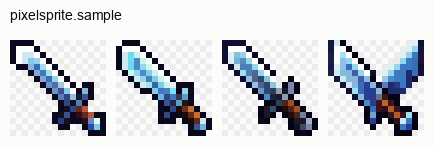

library: 4.2s -> 19.7x faster; identical sprites: True


In [4]:
t = time.time()
lib, _ = sample(model, 4, text, size=16, g_shape=1.0, g_colour=2.0, seed=7, chunk=4, use_filter=False)
t_cache = time.time() - t
display(sheet([rgba_from_index(x, palette) for x in lib], "pixelsprite.sample", scale=6, cols=4))
print(f"library: {t_cache:.1f}s -> {t_naive / t_cache:.1f}x faster; identical sprites: {np.array_equal(mine, lib)}")

## 3. Why is the library faster? The key/value cache
In the naive loop, step t pushes all 18 + t earlier tokens through all 12 layers again, although their
results never change (a token only looks back, never forward). Each layer keeps, for every token, a **key** (what
it offers for matching) and a **value** (what it contributes). The cache stores them, so each step only computes the
**one new** token, which attends to the stored keys and values.

Work per sprite, counted in "token passes through the network":
* naive: (18+1) + (18+2) + … + (18+256) ≈ 37,500;
* with the cache: 18 + 256 = 274.

Attention itself still compares the new token with all earlier ones, so the speed-up is smaller than 37,500 / 274,
but it grows with the length: at 32×32 (1,058 tokens) the naive loop would be hopeless.

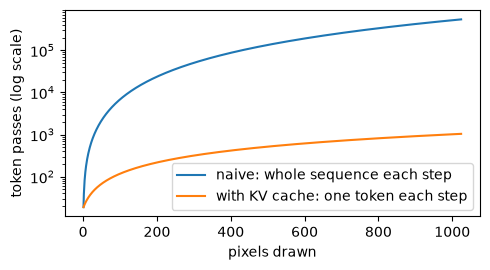

In [5]:
L = np.arange(1, 1025)
plt.figure(figsize=(5, 2.8))
plt.plot(L, np.cumsum(18 + L), label="naive: whole sequence each step")
plt.plot(L, 18 + L, label="with KV cache: one token each step")
plt.yscale("log"); plt.xlabel("pixels drawn"); plt.ylabel("token passes (log scale)"); plt.legend(); plt.tight_layout(); plt.show()

## 4. One seed, one picture
A **seed** fixes the random numbers. Same model + same seed + same device + same batch layout gives the same sprite.
Change any of them and you get a different (equally valid) sprite. That is why the library documents the `chunk`.

In [6]:
a, _ = sample(model, 4, text, size=16, seed=7, chunk=4, use_filter=False)
b, _ = sample(model, 4, text, size=16, seed=7, chunk=2, use_filter=False)
print("same seed, different chunk -> identical?", np.array_equal(a, b))

same seed, different chunk -> identical? False


## You solved the case
You can now: load a model, encode a caption, run the autoregressive loop, guide it, and explain why the cache makes
it fast. Ideas to go further:
1. Add a silhouette (`known = True`, `mask = your drawing`) to `draw_naive` and force EMPTY outside it.
2. Change `split_pick` into a single joint guidance (one g for all 1,025 choices) and compare the swords.
3. Time `draw_naive` at size 32 for one sprite, and estimate how long 16 sprites would take.